# Human-in-the-loop clustering annotation (IMMUcan)

Reviewer request: compare a *real* human clustering annotation with the optimistic greedy assignment
(Leiden clusters → majority ground-truth label).

**Protocol**
1. Same embedding as the Leiden baseline (`src/methods/leiden`): PCA (30) → Harmony on `sample_id` → kNN (k=10).
2. Initial Leiden clustering, then iterative **blind** annotation: inspect marker heatmaps, merge / subcluster, assign labels.
   Ground-truth columns are kept out of `adata` and are only used in the final *Evaluation* section.
3. `suggest()` proposes a next step per cluster from prior-knowledge marker signatures (not from the ground truth);
   the annotator makes the final call. Every action is logged with a timestamp and auto-saved (`OUTPUT_DIR`).
4. Evaluation: human labels vs. greedy assignment on the initial Leiden clusters (the benchmark heuristic).

Kernel: `scimap_tspc` (scanpy + harmonypy).

In [1]:
import json
import sys
import time
from pathlib import Path

import anndata as ad
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
import seaborn as sns
from sklearn.metrics import cohen_kappa_score, f1_score, matthews_corrcoef

sys.path.insert(0, str(Path.cwd().parent / "methods" / "utils"))
from greedy_f1_utils import greedy_f1_score

In [2]:
sc.settings.n_jobs = 6

## Config

In [ ]:
DATA_PATH = Path("/Users/lukashat/Documents/PhD_Schapiro/Projects/phenotype_benchmark/datasets/IMMUcan_quantification.csv")
OUTPUT_DIR = Path("/Users/lukashat/Documents/PhD_Schapiro/Projects/phenotype_benchmark/human_clustering/IMMUcan")
ANNOTATOR = "Lukas"
RESUME = True  # continue a saved annotation session from OUTPUT_DIR if one exists

BATCH_KEY = "sample_id"
GT_COLS = ["level_1_cell_type", "level_2_cell_type", "cell_type"]
SEED = 0
INITIAL_RESOLUTION = 1.0
LEIDEN_KWARGS = dict(flavor="igraph", n_iterations=2, directed=False, random_state=SEED)

# same markers as the Leiden baseline (nuclear/DNA channels excluded); used for the embedding
MARKERS = [
    "MPO", "SMA", "CD16", "CD38", "HLADR", "CD27", "CD15", "CD45RA", "CD163", "B2M", "CD20", "CD68", "Ido1",
    "CD3", "LAG3", "CD11c", "PD1", "PDGFRb", "CD7", "GrzB", "PDL1", "TCF7", "CD45RO", "FOXP3", "ICOS", "CD8a",
    "CarbonicAnhydrase", "CD33", "Ki67", "VISTA", "CD40", "CD4", "CD14", "Ecad", "CD303", "CD206", "cleavedPARP",
]

# heatmap layout only; a marker may appear in several groups
MARKER_GROUPS = {
    "Tumor": ["Ecad", "CarbonicAnhydrase"],
    "Stroma": ["SMA", "PDGFRb"],
    "T/NK": ["CD3", "CD4", "CD8a", "FOXP3", "CD7", "GrzB", "CD16"],
    "B/Plasma": ["CD20", "CD27", "CD38"],
    "Myeloid": ["CD68", "CD163", "CD206", "CD14", "CD11c", "HLADR", "CD33", "CD40", 'CD16'],
    "Granulocyte": ["MPO", "CD15", 'CD16'],
    "pDC": ["CD303"],
    "State": ["Ki67", "PD1", "PDL1", "LAG3", "ICOS", "TCF7", "CD45RO", "Ido1", "VISTA", "B2M", "cleavedPARP"],
}
assert {m for group in MARKER_GROUPS.values() for m in group} <= set(MARKERS)

# label vocabulary of the benchmark (level 3); annotations must use these names
LABELS = [
    "Cancer", "Stroma", "CD8+_T_cell", "CD4+_T_cell", "Treg", "B_cell", "BnT", "Plasma_cell", "NK_cell",
    "M2_Macrophage", "Neutrophil", "Dendritic_cell", "Plasmacytoid_dendritic_cell", "undefined",
]

# Prior-knowledge marker signatures (panel/literature knowledge, NOT derived from the ground truth).
# Only used by suggest(). "pos" markers are averaged; a tuple inside "pos" means "any of these" (max).
# "neg" markers penalise a label only where they are above average.
SIGNATURES = {
    "Cancer": {"pos": [("Ecad", "CarbonicAnhydrase")]},
    "Stroma": {"pos": ["SMA", "PDGFRb"]},
    "CD8+_T_cell": {"pos": ["CD3", "CD8a"]},
    "CD4+_T_cell": {"pos": ["CD3", "CD4"], "neg": ["FOXP3"]},
    "Treg": {"pos": ["CD3", "CD4", "FOXP3"]},
    "B_cell": {"pos": ["CD20"]},
    "BnT": {"pos": ["CD20", "CD3"]},
    "Plasma_cell": {"pos": ["CD38"]},
    "NK_cell": {"pos": ["CD7", "GrzB"], "neg": ["CD3"]},
    "M2_Macrophage": {"pos": ["CD68", "CD163", "CD206"]},
    "Neutrophil": {"pos": ["MPO", "CD15"]},
    "Dendritic_cell": {"pos": ["CD11c", "HLADR"], "neg": ["CD68"]},
    "Plasmacytoid_dendritic_cell": {"pos": ["CD303"]},
}
assert set(SIGNATURES) <= set(LABELS)

## Load and embed

Intensities are already arcsinh-transformed, so no further transformation. For heatmaps and signature scores,
each marker is clipped at its 99.9th percentile and z-scored over all cells (z > 0 = above the dataset average).
The clustering itself uses the same input as the baseline.

In [ ]:
df = pd.read_csv(DATA_PATH)
# ground truth stays outside `adata` until the evaluation section
gt = df[GT_COLS].copy()

adata = ad.AnnData(
    X=df[MARKERS].to_numpy(dtype=np.float32),
    obs=df[["sample_id", "cell_id"]].astype({"sample_id": "category"}).set_index(df.index.astype(str)),
)
adata.var_names = MARKERS

clipped = np.minimum(adata.X, np.percentile(adata.X, 99.9, axis=0))
adata.layers["z"] = (clipped - clipped.mean(axis=0)) / clipped.std(axis=0)
Z = pd.DataFrame(adata.layers["z"], index=adata.obs_names, columns=MARKERS)
adata

In [ ]:
sc.pp.pca(adata, n_comps=30, random_state=SEED)
sc.external.pp.harmony_integrate(adata, BATCH_KEY, basis="X_pca", adjusted_basis="X_harmony")
sc.pp.neighbors(adata, n_neighbors=10, use_rep="X_harmony", random_state=SEED)

sc.tl.leiden(adata, resolution=INITIAL_RESOLUTION, key_added="leiden_init", **LEIDEN_KWARGS)
adata.obs["cluster"] = adata.obs["leiden_init"].copy()
annotation = {}  # cluster -> label
history = []  # log of all annotation actions

## Helper functions

In [27]:
def cluster_means(labels):
    """Mean z-scored expression per group of `labels` (Series indexed by obs_names, may be a subset)."""
    return Z.groupby(labels, observed=True).mean()


def signature_scores(means):
    """Score cluster mean profiles against SIGNATURES: mean z of pos markers (max within a tuple)
    - mean positive z of neg markers."""
    scores = {}
    for label, sig in SIGNATURES.items():
        pos = [means[list(m)].max(axis=1) if isinstance(m, tuple) else means[m] for m in sig["pos"]]
        score = pd.concat(pos, axis=1).mean(axis=1)
        if "neg" in sig:
            score = score - means[sig["neg"]].clip(lower=0).mean(axis=1)
        scores[label] = score
    return pd.DataFrame(scores)


def trial_split(cluster, resolution, min_frac):
    """Subcluster `cluster` without changing the state and return the cell fractions of the best-scoring
    labels of its subclusters (labels covering < min_frac of the cells are dropped)."""
    sc.tl.leiden(adata, resolution=resolution, restrict_to=("cluster", [cluster]), key_added="_trial", **LEIDEN_KWARGS)
    sub = adata.obs.loc[adata.obs["cluster"] == cluster, "_trial"]
    del adata.obs["_trial"]
    best = signature_scores(cluster_means(sub)).idxmax(axis=1)
    frac = sub.map(best).value_counts(normalize=True)
    return frac[frac >= min_frac]


def suggest(clusters=None, resolution=0.5, min_score=0.5, min_margin=0.3, min_frac=0.1,
            max_sample_frac=0.5, merge_corr=0.9):
    """Per-cluster summary with a suggested next step.

    - subcluster: a trial subclustering splits the cluster into >= 2 different signature labels
    - check: no signature reaches `min_score` (candidate for 'undefined', or inspect manually)
    - annotate: one clear best label ("close to X" if the runner-up is within `min_margin`)
    merge_with lists clusters with the same best label and a mean profile correlation > `merge_corr`.
    Clusters dominated by one sample are flagged (expected for tumour cells, suspicious otherwise).
    """
    labels = adata.obs["cluster"]
    means = cluster_means(labels)
    scores = signature_scores(means)
    best = scores.idxmax(axis=1)
    corr = means.T.corr()
    rows = []
    for c in clusters or means.index:
        top2 = scores.loc[c].nlargest(2)
        margin = top2.iloc[0] - top2.iloc[1]
        split = trial_split(c, resolution, min_frac)
        if len(split) > 1:
            action = "subcluster -> " + " / ".join(f"{l} {f:.0%}" for l, f in split.items())
        elif top2.iloc[0] < min_score:
            action = "check: no clear signature"
        else:
            action = f"annotate as {top2.index[0]}" + (f" (close to {top2.index[1]})" if margin < min_margin else "")
        samples = adata.obs.loc[labels == c, BATCH_KEY].value_counts(normalize=True)
        if samples.iloc[0] > max_sample_frac:
            action += f" | {samples.iloc[0]:.0%} from one sample"
        partners = corr[c].drop(c)
        rows.append({
            "cluster": c,
            "n_cells": int((labels == c).sum()),
            "top_markers": " ".join(f"{m}+" for m in means.loc[c].nlargest(4).index),
            "best": top2.index[0],
            "score": top2.iloc[0],
            "runner_up": top2.index[1],
            "margin": margin,
            "merge_with": ", ".join(o for o in partners[partners > merge_corr].index if best[o] == top2.index[0]),
            "annotation": annotation.get(c, ""),
            "suggestion": action,
        })
    return pd.DataFrame(rows).set_index("cluster").round(2)


def show(clusters=None, violin_markers=None):
    """Heatmap of mean z-scores per cluster (default: all clusters, ordered by similarity).
    Annotated cells are pooled per label, so labels appear as one row each.
    `violin_markers` adds per-cell distributions; bimodal markers hint at mixed clusters."""
    labels = adata.obs["cluster"].astype(str)
    mask = np.ones(adata.n_obs, dtype=bool) if clusters is None else labels.isin(clusters).to_numpy()
    labels = labels[mask]
    n = labels.value_counts()
    pl = ad.AnnData(
        X=adata.layers["z"][mask],
        obs=pd.DataFrame({"group": pd.Categorical(labels.map({c: f"{c} (n={n[c]})" for c in n.index}))}, index=labels.index),
        obsm={"X_harmony": adata.obsm["X_harmony"][mask]},
    )
    pl.var_names = MARKERS
    dendrogram = len(n) > 2
    if dendrogram:
        sc.tl.dendrogram(pl, "group", use_rep="X_harmony")
    sc.pl.matrixplot(pl, MARKER_GROUPS, "group", dendrogram=dendrogram, cmap="RdBu_r", vmin=-2, vmax=2,
                     colorbar_title="mean z-score")
    if violin_markers:
        sc.pl.violin(pl, violin_markers, groupby="group", stripplot=False, rotation=90)


def save_state():
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    adata.obs[["sample_id", "cell_id", "cluster"]].to_csv(OUTPUT_DIR / "clusters.csv", index=False)
    state = {"annotator": ANNOTATOR, "annotation": annotation, "history": history}
    (OUTPUT_DIR / "annotation.json").write_text(json.dumps(state, indent=2))


def load_state():
    saved = pd.read_csv(OUTPUT_DIR / "clusters.csv", dtype={"cluster": str})
    assert (saved["cell_id"].to_numpy() == adata.obs["cell_id"].to_numpy()).all()
    assert (saved["sample_id"].to_numpy() == adata.obs["sample_id"].astype(str).to_numpy()).all()
    adata.obs["cluster"] = pd.Categorical(saved["cluster"].to_numpy())
    state = json.loads((OUTPUT_DIR / "annotation.json").read_text())
    annotation.clear()
    annotation.update(state["annotation"])
    history[:] = state["history"]


def _log(action, **kwargs):
    history.append({"time": time.strftime("%Y-%m-%d %H:%M:%S"), "action": action, **kwargs})
    save_state()


def subcluster(cluster, resolution=0.5):
    """Split `cluster` into '<cluster>,0', '<cluster>,1', ... and show the result."""
    sc.tl.leiden(adata, resolution=resolution, restrict_to=("cluster", [cluster]), key_added="cluster", **LEIDEN_KWARGS)
    annotation.pop(cluster, None)
    _log("subcluster", cluster=cluster, resolution=resolution)
    new = [c for c in adata.obs["cluster"].cat.categories if c.startswith(f"{cluster},")]
    show(new)
    return suggest(new)


def merge(clusters, name=None):
    """Merge `clusters` into one cluster (named after the first one by default); drops their annotations."""
    name = name or clusters[0]
    merged = adata.obs["cluster"].astype(str).replace(dict.fromkeys(clusters, name))
    adata.obs["cluster"] = pd.Categorical(merged)
    for c in clusters:
        annotation.pop(c, None)
    _log("merge", clusters=list(clusters), name=name)


def annotate(mapping):
    """Assign labels and merge each cluster into the cluster named after its label,
    e.g. annotate({"0": "Cancer", "3,1": "Treg"}) moves the cells of "0" into "Cancer" and of "3,1" into "Treg"."""
    unknown_labels = set(mapping.values()) - set(LABELS)
    unknown_clusters = set(mapping) - set(adata.obs["cluster"].cat.categories)
    assert not unknown_labels, f"labels not in LABELS: {unknown_labels}"
    assert not unknown_clusters, f"clusters do not exist: {unknown_clusters}"
    renamed = adata.obs["cluster"].astype(str).replace(mapping)
    adata.obs["cluster"] = pd.Categorical(renamed)
    for c in mapping:
        annotation.pop(c, None)
    annotation.update({label: label for label in mapping.values()})
    _log("annotate", mapping=mapping)


if RESUME and (OUTPUT_DIR / "clusters.csv").exists():
    load_state()
    print(f"Resumed session: {adata.obs['cluster'].nunique()} clusters, {len(annotation)} annotated, {len(history)} actions")

Resumed session: 56 clusters, 17 annotated, 8 actions


## Annotation

Loop until every cluster is annotated:
- `show()` / `show(["3", "7"], violin_markers=["CD3", "CD8a", "CD4"])`: inspect marker expression
- `suggest()` / `suggest(["3", "7"])`: summary table with a suggested next step (runs a trial subclustering per cluster)
- `subcluster("3", resolution=0.5)`, `merge(["5", "9"])`, `annotate({"0": "Cancer"})`: edit (logged and auto-saved).
  `annotate` merges the cluster into the cluster named after its label, so annotated cells appear as one row per cell type.

categories: B_cell (n=7949), BnT (n=9720), CD4+_T_cell (n=21897), etc.
var_group_labels: Tumor, Stroma, T/NK, etc.


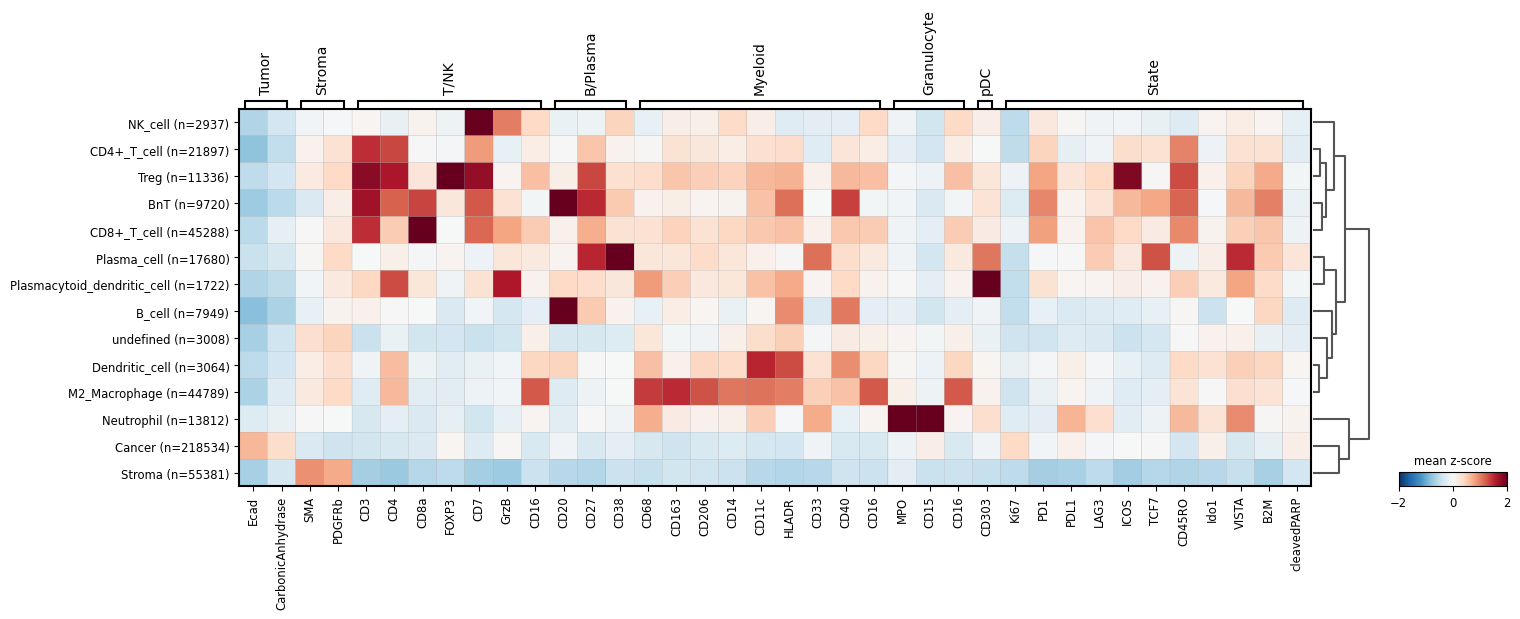

In [2234]:
show()

In [190]:
suggest()

,n_cells,top_markers,best,score,runner_up,margin,merge_with,annotation,suggestion
cluster,,,,,,,,,
0,50676,CD68+ CD163+ CD16+ CD206+,M2_Macrophage,1.30,Neutrophil,1.00,,,subcluster -> M2_Macrophage 66% / Neutrophil 31%
1,21513,CD15+ MPO+ SMA+ VISTA+,Neutrophil,1.53,Stroma,1.41,,,subcluster -> Neutrophil 63% / Cancer 21% / St...
10,56700,Ecad+ CarbonicAnhydrase+ cleavedPARP+ Ido1+,Cancer,0.69,Neutrophil,0.94,,,annotate as Cancer
11,18299,CD3+ CD4+ CD45RO+ CD7+,Treg,1.05,CD4+_T_cell,0.23,,,subcluster -> CD4+_T_cell 79% / Treg 21%
13,12251,Ecad+ GrzB+ PDL1+ Ido1+,Cancer,1.25,Plasmacytoid_dendritic_cell,0.53,,,annotate as Cancer
14,8226,CarbonicAnhydrase+ Ki67+ Ecad+ cleavedPARP+,Cancer,1.89,B_cell,1.89,,,annotate as Cancer
15,23,CD33+ PDL1+ cleavedPARP+ CD68+,Cancer,0.23,Stroma,0.01,,,subcluster -> Plasmacytoid_dendritic_cell 61% ...
16,26303,CD8a+ CD3+ CD7+ CD45RO+,CD8+_T_cell,1.73,CD4+_T_cell,1.10,,,annotate as CD8+_T_cell
17,111,Ecad+ CD15+ Ki67+ GrzB+,Cancer,1.02,Neutrophil,0.52,,,annotate as Cancer | 91% from one sample


In [ ]:
# examples (commented out so "Run All" does not change the annotation):
# show(["3", "7"], violin_markers=["CD3", "CD8a", "CD4", "FOXP3"])
# subcluster("3", resolution=0.5)
# merge(["5", "9"])
# annotate({"0": "Cancer", "1": "Stroma"})

categories: 7,0 (n=17), 7,1 (n=29), 7,2 (n=24), etc.
var_group_labels: Tumor, Stroma, T/NK, etc.


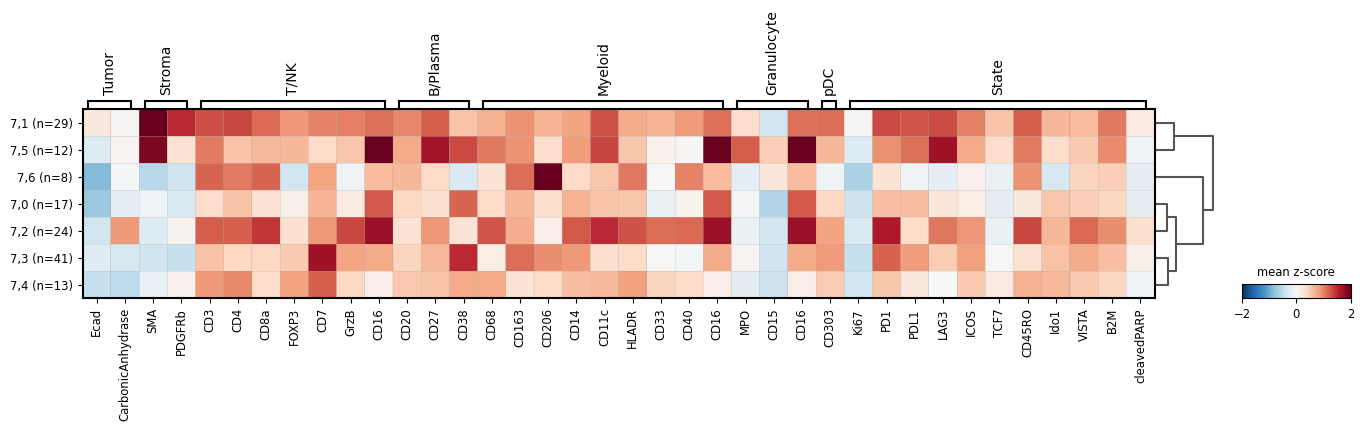

,n_cells,top_markers,best,score,runner_up,margin,merge_with,annotation,suggestion
cluster,,,,,,,,,
"7,0",17,CD16+ CD38+ CD14+ CD7+,Plasma_cell,1.16,M2_Macrophage,0.70,,,subcluster -> Plasma_cell 65% / Cancer 35%
"7,1",29,SMA+ PDGFRb+ CD4+ PD1+,Stroma,1.97,CD8+_T_cell,0.76,,,subcluster -> Stroma 83% / CD4+_T_cell 17%
"7,2",24,CD16+ PD1+ CD11c+ CD8a+,CD8+_T_cell,1.32,Treg,0.41,,,annotate as CD8+_T_cell
"7,3",41,CD7+ CD38+ PD1+ CD163+,Plasma_cell,1.50,Plasmacytoid_dendritic_cell,0.64,,,subcluster -> Plasma_cell 76% / Plasmacytoid_d...
"7,4",13,CD7+ CD4+ CD3+ HLADR+,Treg,0.88,Plasma_cell,0.13,,,subcluster -> Plasma_cell 69% / Treg 31%
"7,5",12,CD16+ SMA+ LAG3+ CD27+,Plasma_cell,1.32,Stroma,0.23,,,annotate as Plasma_cell (close to Stroma)
"7,6",8,CD206+ CD3+ CD8a+ CD163+,M2_Macrophage,1.26,CD8+_T_cell,0.09,,,subcluster -> CD8+_T_cell 62% / B_cell 38%


In [2231]:
subcluster("7", resolution=0.6)

In [2232]:
annotate({"7,1": "Stroma", "7,4": "CD4+_T_cell", "7,0": "CD4+_T_cell", "7,5": "undefined"})


In [2078]:
merge(["7,1", "7,2"], name="7,1")

In [1315]:
annotate({"60,13":"Cancer", "60,8":"Cancer", "60,4":"undefined", "60,7":"Cancer", "60,11":"Dendritic_cell"})


In [2174]:
annotate({"7,5,14": "CD8+_T_cell", "7,5,18": "Treg", "7,5,11": "Treg"})


In [2230]:
sub = [c for c in adata.obs["cluster"].cat.categories if c.startswith("7,")]
print(sub)          # check the list first
merge(sub, name="7")          # merged cluster is named after the first entry, e.g. "5,0,5,0"


['7,0', '7,1', '7,11', '7,2', '7,3', '7,4', '7,5', '7,7', '7,9']


In [2233]:
sub = [c for c in adata.obs["cluster"].cat.categories if c.startswith("7,")]
print(sub)          # check the list first
annotate({c: "CD8+_T_cell" for c in sub})
        # merged cluster is named after the first entry, e.g. "5,0,5,0"


['7,2', '7,3', '7,6']


In [2236]:
from sklearn.metrics import classification_report

levels = {"level1": "level_1_cell_type", "level2": "level_2_cell_type", "level3": "cell_type"}
hierarchy = gt.drop_duplicates("cell_type").set_index("cell_type")

# human level-3 labels; clusters not yet annotated -> "unannotated"
human = adata.obs["cluster"].astype(str).map(annotation).fillna("unannotated").to_numpy()
print(f"{(human == 'unannotated').mean():.1%} of cells unannotated")

reports = {}
for level, col in levels.items():
    y_true = gt[col].to_numpy()
    # derive level 1/2 from level 3 via the GT hierarchy (keeps "unannotated" as is)
    y_pred = human if col == "cell_type" else pd.Series(human).map(hierarchy[col]).fillna("unannotated").to_numpy()
    print(f"===== {level} ({col}) =====")
    print(classification_report(y_true, y_pred, digits=3, zero_division=0))
    reports[level] = pd.DataFrame(
        classification_report(y_true, y_pred, output_dict=True, zero_division=0)
    ).T.round(3)


0.0% of cells unannotated
===== level1 (level_1_cell_type) =====
              precision    recall  f1-score   support

      Cancer      0.865     0.897     0.881    210853
      Immune      0.860     0.874     0.867    177270
     Stromal      0.615     0.679     0.646     50127
   undefined      0.354     0.057     0.097     18867

    accuracy                          0.829    457117
   macro avg      0.674     0.627     0.623    457117
weighted avg      0.815     0.829     0.817    457117

===== level2 (level_2_cell_type) =====
                 precision    recall  f1-score   support

         Cancer      0.865     0.897     0.881    210853
Lymphoid_immune      0.852     0.860     0.856    115652
 Myeloid_immune      0.661     0.680     0.670     61618
         Stroma      0.615     0.679     0.646     50127
      undefined      0.354     0.057     0.097     18867

       accuracy                          0.800    457117
      macro avg      0.669     0.635     0.630    457117
   

In [2237]:
out = df.copy()
out["predicted"] = adata.obs["cluster"].astype(str).map(annotation).fillna("unannotated").to_numpy()
out.to_csv(OUTPUT_DIR / "IMMUcan_human_clustering.csv", index=False)
out[["cell_type", "predicted"]].head()


,cell_type,predicted
0,M2_Macrophage,M2_Macrophage
1,Plasma_cell,Cancer
2,Stroma,Stroma
3,Cancer,Cancer
4,Dendritic_cell,M2_Macrophage
